# Pooling Usage — Facility Only (fac=1, amb=0)

How much cross-battalion routing actually occurs under facility pooling?
Does the greedy dispatcher ever send patients to the neighbor R1?

In [32]:
import sys
from pathlib import Path
_root = Path(".").resolve()
while not (_root / "paths.py").exists():
    _root = _root.parent
sys.path.insert(0, str(_root))

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

RESULTS_PATH = _root / "data_cluster" / "sobol_no_t2_fixed_pooling" / "results.csv"
df = pd.read_csv(RESULTS_PATH)
print(f"Loaded {len(df)} runs")
print(f"Columns: {df.columns.tolist()}")

UNCERTAINTIES = ["ccp_r1_same_bn_min", "bcas_rate", "waves_per_day", "wave_duration_min"]

Loaded 98304 runs
Columns: ['ccp_r1_same_bn_min', 'ccp_r1_inter_bn_min', 'bcas_rate', 'waves_per_day', 'wave_duration_min', 'facility_eligibility', 'ambulance_eligibility', 'scenario', 'policy', 'model', 'death_rate_T1_BCAS', 'death_rate_T2_BCAS', 'death_rate_T3_BCAS', 'n_patients_T1_BCAS', 'n_patients_T2_BCAS', 'n_patients_T3_BCAS', 'median_wait_ccp_transport_T1', 'median_wait_ccp_transport_T2', 'median_wait_r1_care_T1', 'median_wait_r1_care_T2', 'median_wait_r1_transport_T1', 'median_wait_r1_transport_T2', 'median_wait_r2_care_T1', 'median_wait_r2_care_T2', 'mortality_ccp_transport_T1', 'mortality_ccp_transport_T2', 'mortality_r1_care_T1', 'mortality_r1_care_T2', 'mortality_r1_transport_T1', 'mortality_r1_transport_T2', 'mortality_r2_care_T1', 'mortality_r2_care_T2', 'frac_facility_cross_bn', 'frac_transport_cross_bn']


In [33]:
fac = df[(df["facility_eligibility"] == 1) & (df["ambulance_eligibility"] == 0)].reset_index(drop=True)
stove = df[(df["facility_eligibility"] == 0) & (df["ambulance_eligibility"] == 0)].reset_index(drop=True)
amb = df[(df["facility_eligibility"] == 0) & (df["ambulance_eligibility"] == 1)].reset_index(drop=True)
both = df[(df["facility_eligibility"] == 1) & (df["ambulance_eligibility"] == 1)].reset_index(drop=True)

print(f"Fac only: {len(fac)} runs")

if "frac_facility_cross_bn" in fac.columns:
    print(f"\nFacility cross-bn fraction:")
    print(f"  Mean:   {fac['frac_facility_cross_bn'].mean():.4f}")
    print(f"  Median: {fac['frac_facility_cross_bn'].median():.4f}")
    print(f"  Min:    {fac['frac_facility_cross_bn'].min():.4f}")
    print(f"  Max:    {fac['frac_facility_cross_bn'].max():.4f}")
    print(f"  Zero:   {(fac['frac_facility_cross_bn'] == 0).sum()} / {len(fac)} ({(fac['frac_facility_cross_bn'] == 0).mean():.1%})")
else:
    print("frac_facility_cross_bn not in results — re-run experiment with pooling fraction outcomes")

if "frac_transport_cross_bn" in fac.columns:
    print(f"\nTransport cross-bn fraction:")
    print(f"  Mean:   {fac['frac_transport_cross_bn'].mean():.4f}")
    print(f"  Median: {fac['frac_transport_cross_bn'].median():.4f}")
    print(f"  Zero:   {(fac['frac_transport_cross_bn'] == 0).sum()} / {len(fac)} ({(fac['frac_transport_cross_bn'] == 0).mean():.1%})")

Fac only: 24576 runs

Facility cross-bn fraction:
  Mean:   0.2433
  Median: 0.2000
  Min:    0.0000
  Max:    1.0000
  Zero:   2807 / 24576 (11.4%)

Transport cross-bn fraction:
  Mean:   0.0000
  Median: 0.0000
  Zero:   24576 / 24576 (100.0%)


## Pooling Usage Distribution — All 4 Policies

C:\Users\User\AppData\Local\Temp\ipykernel_1712\224994065.py:11: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = axes[0].boxplot(data_fac, labels=[l for l, _, _ in policies], patch_artist=True, widths=0.6)
C:\Users\User\AppData\Local\Temp\ipykernel_1712\224994065.py:23: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = axes[1].boxplot(data_trn, labels=[l for l, _, _ in policies], patch_artist=True, widths=0.6)


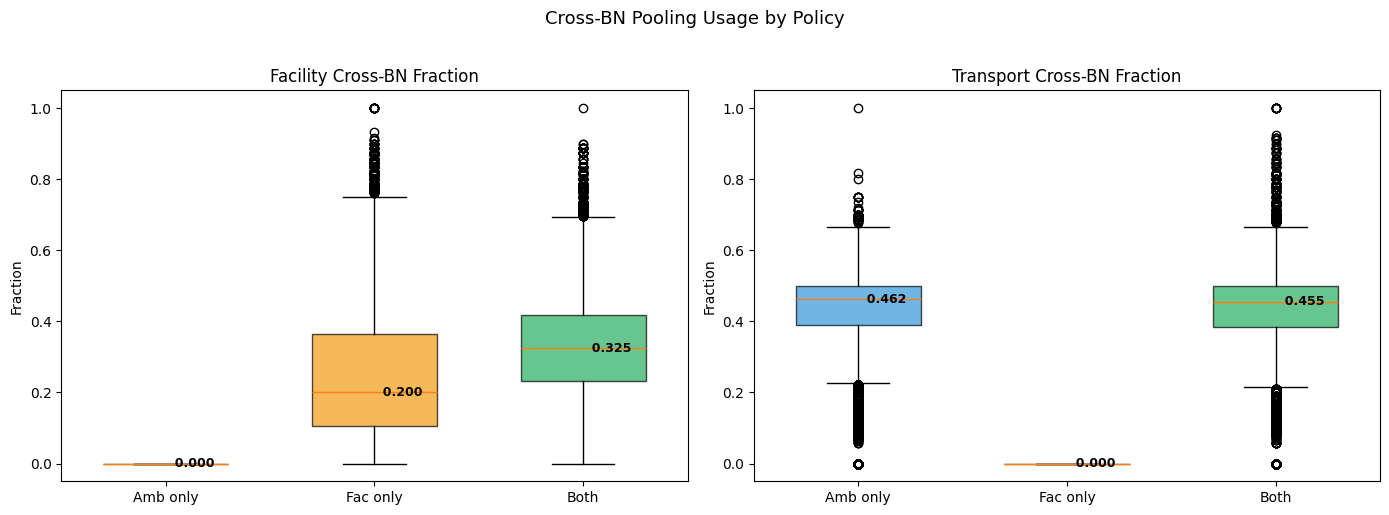

In [34]:
policies = [
    ("Amb only", amb, "#3498db"),
    ("Fac only", fac, "#f39c12"),
    ("Both", both, "#27ae60"),
]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Facility cross-bn boxplots
data_fac = [sub["frac_facility_cross_bn"].dropna().values for _, sub, _ in policies]
bp = axes[0].boxplot(data_fac, labels=[l for l, _, _ in policies], patch_artist=True, widths=0.6)
for patch, (_, _, color) in zip(bp["boxes"], policies):
    patch.set_facecolor(color)
    patch.set_alpha(0.7)
for i, d in enumerate(data_fac):
    med = np.median(d)
    axes[0].text(i + 1, med, f"  {med:.3f}", va="center", fontsize=9, fontweight="bold")
axes[0].set_ylabel("Fraction")
axes[0].set_title("Facility Cross-BN Fraction")

# Transport cross-bn boxplots
data_trn = [sub["frac_transport_cross_bn"].dropna().values for _, sub, _ in policies]
bp = axes[1].boxplot(data_trn, labels=[l for l, _, _ in policies], patch_artist=True, widths=0.6)
for patch, (_, _, color) in zip(bp["boxes"], policies):
    patch.set_facecolor(color)
    patch.set_alpha(0.7)
for i, d in enumerate(data_trn):
    med = np.median(d)
    axes[1].text(i + 1, med, f"  {med:.3f}", va="center", fontsize=9, fontweight="bold")
axes[1].set_ylabel("Fraction")
axes[1].set_title("Transport Cross-BN Fraction")

fig.suptitle("Cross-BN Pooling Usage by Policy", fontsize=13, y=1.02)
plt.tight_layout()
plt.show()

## Facility Pooling Usage vs Each Uncertainty

C:\Users\User\AppData\Local\Temp\ipykernel_1712\2572012103.py:10: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot(data, labels=labels, patch_artist=True, widths=0.6)
C:\Users\User\AppData\Local\Temp\ipykernel_1712\2572012103.py:10: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot(data, labels=labels, patch_artist=True, widths=0.6)
C:\Users\User\AppData\Local\Temp\ipykernel_1712\2572012103.py:10: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot(data, labels=labels, patch_artist=True, widths=0.6)
C:\Users\User\AppData\Local\Temp\ipykernel_1712\2572012103.py:10: MatplotlibDeprecati

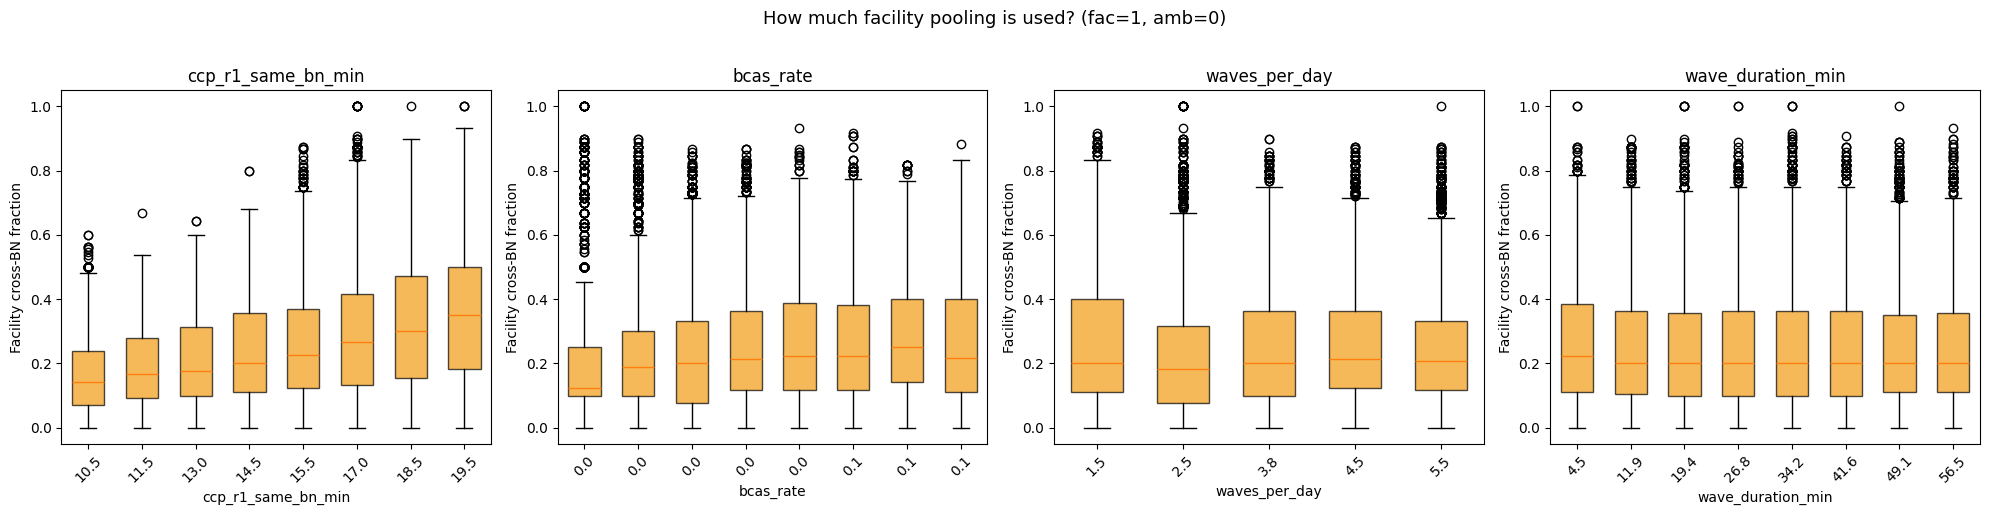

In [35]:
if "frac_facility_cross_bn" in fac.columns:
    fig, axes = plt.subplots(1, len(UNCERTAINTIES), figsize=(5 * len(UNCERTAINTIES), 5))

    for ax, col in zip(axes, UNCERTAINTIES):
        bins = pd.qcut(fac[col], q=8, duplicates="drop")
        groups = fac.groupby(bins, observed=True)
        labels = [f"{iv.mid:.1f}" for iv in groups.groups.keys()]
        data = [g["frac_facility_cross_bn"].values for _, g in groups]

        bp = ax.boxplot(data, labels=labels, patch_artist=True, widths=0.6)
        for patch in bp["boxes"]:
            patch.set_facecolor("#f39c12")
            patch.set_alpha(0.7)
        ax.set_xlabel(col)
        ax.set_ylabel("Facility cross-BN fraction")
        ax.set_title(col)
        ax.tick_params(axis="x", rotation=45)

    fig.suptitle("How much facility pooling is used? (fac=1, amb=0)", fontsize=13, y=1.02)
    plt.tight_layout()
    plt.show()
else:
    print("No frac_facility_cross_bn column.")

## Pooling Usage vs Mortality — Does more pooling help?

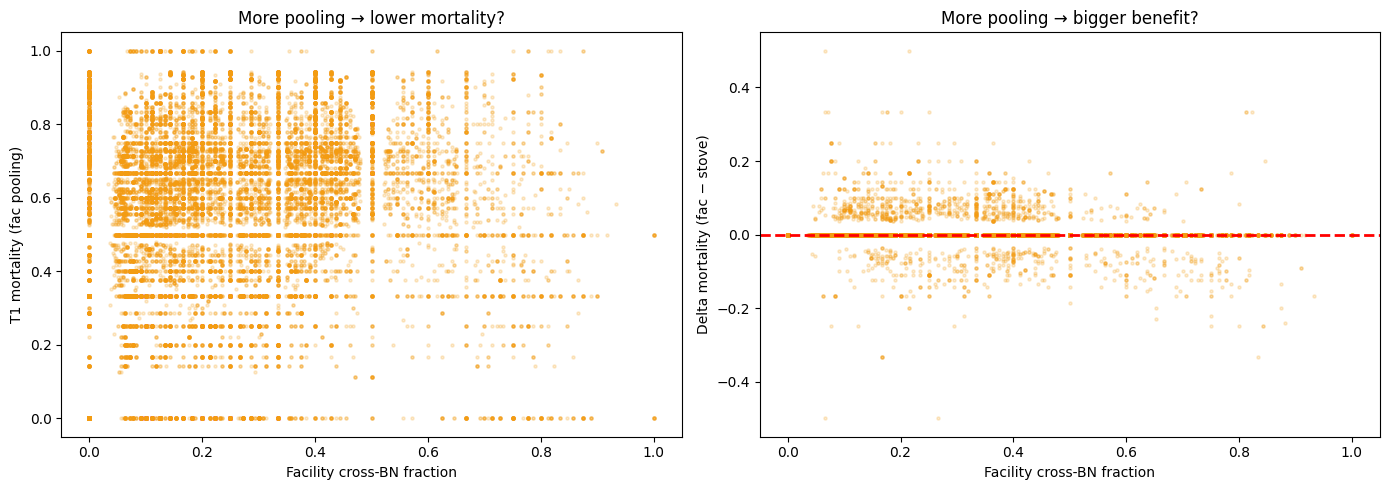

                   n  mean_mort  mean_delta  mean_pooling
pool_bin                                                 
(-0.001, 0.2]  12614     0.5422      0.0019        0.1008
(0.2, 0.4]      7647     0.5682      0.0028        0.3086
(0.4, 0.6]      3177     0.6742      0.0003        0.4804
(0.6, 0.8]       966     0.5243     -0.0076        0.6981
(0.8, 1.0]       172     0.4212     -0.0059        0.8579


In [36]:
if "frac_facility_cross_bn" in fac.columns:
    fac_sorted = fac.sort_values("scenario").reset_index(drop=True)
    stove_sorted = stove.sort_values("scenario").reset_index(drop=True)
    assert (fac_sorted["scenario"].values == stove_sorted["scenario"].values).all()

    delta = fac_sorted["death_rate_T1_BCAS"].values - stove_sorted["death_rate_T1_BCAS"].values

    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    # Pooling usage vs mortality
    axes[0].scatter(fac_sorted["frac_facility_cross_bn"], fac_sorted["death_rate_T1_BCAS"],
                    alpha=0.2, s=5, color="#f39c12")
    axes[0].set_xlabel("Facility cross-BN fraction")
    axes[0].set_ylabel("T1 mortality (fac pooling)")
    axes[0].set_title("More pooling → lower mortality?")

    # Pooling usage vs delta
    axes[1].scatter(fac_sorted["frac_facility_cross_bn"], delta,
                    alpha=0.2, s=5, color="#f39c12")
    axes[1].axhline(0, color="red", linewidth=2, linestyle="--")
    axes[1].set_xlabel("Facility cross-BN fraction")
    axes[1].set_ylabel("Delta mortality (fac − stove)")
    axes[1].set_title("More pooling → bigger benefit?")

    plt.tight_layout()
    plt.show()

    # Summary table by pooling usage bins
    fac_sorted["delta"] = delta
    fac_sorted["pool_bin"] = pd.cut(fac_sorted["frac_facility_cross_bn"], bins=5)
    summary = fac_sorted.groupby("pool_bin", observed=True).agg(
        n=("death_rate_T1_BCAS", "count"),
        mean_mort=("death_rate_T1_BCAS", "mean"),
        mean_delta=("delta", "mean"),
        mean_pooling=("frac_facility_cross_bn", "mean"),
    )
    print(summary.to_string(float_format="%.4f"))
else:
    print("No frac_facility_cross_bn column.")

## Mortality: Low Pooling vs High Pooling

Split scenarios at the median pooling fraction. Does more cross-bn routing correlate with different mortality?

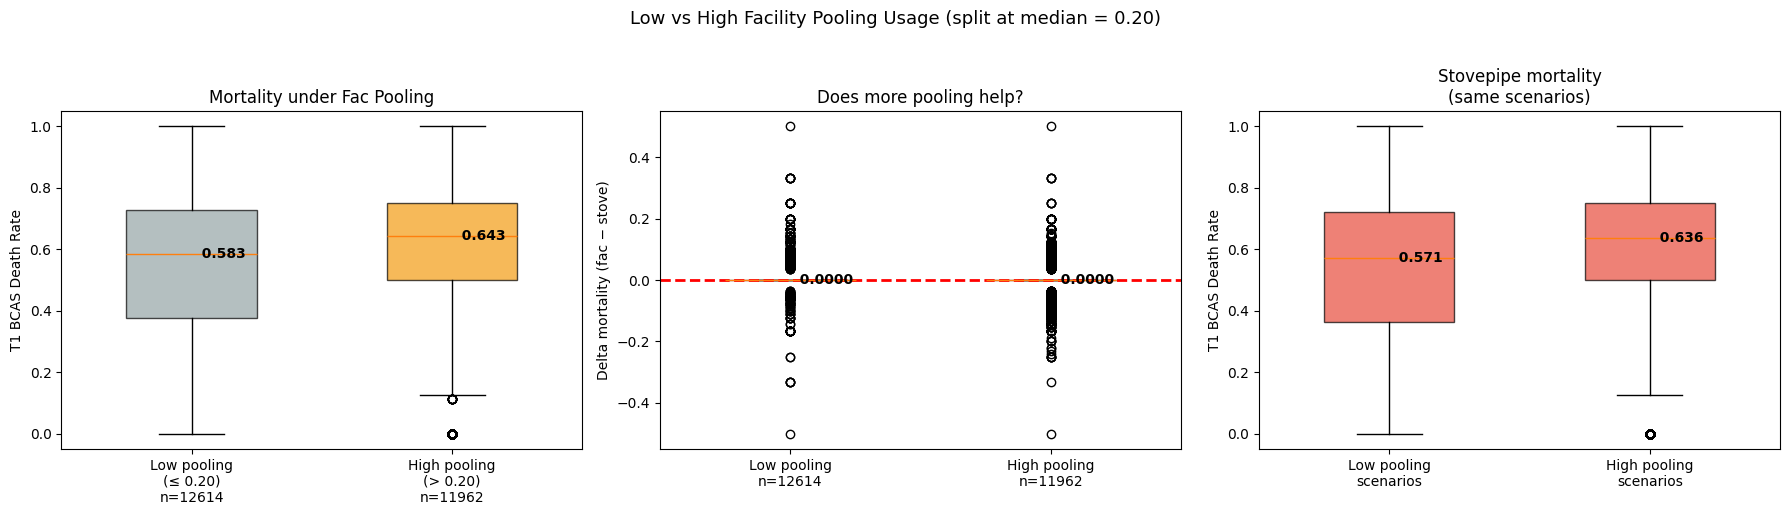

Low pooling:  fac mort median=0.583, delta median=0.0000
High pooling: fac mort median=0.643, delta median=0.0000


In [37]:
fac_sorted = fac.sort_values("scenario").reset_index(drop=True)
stove_sorted = stove.sort_values("scenario").reset_index(drop=True)
assert (fac_sorted["scenario"].values == stove_sorted["scenario"].values).all()

median_pooling = fac_sorted["frac_facility_cross_bn"].median()
low = fac_sorted[fac_sorted["frac_facility_cross_bn"] <= median_pooling]
high = fac_sorted[fac_sorted["frac_facility_cross_bn"] > median_pooling]

delta_low = low["death_rate_T1_BCAS"].values - stove_sorted.loc[low.index, "death_rate_T1_BCAS"].values
delta_high = high["death_rate_T1_BCAS"].values - stove_sorted.loc[high.index, "death_rate_T1_BCAS"].values

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Mortality boxplots
bp = axes[0].boxplot([low["death_rate_T1_BCAS"].values, high["death_rate_T1_BCAS"].values],
                      tick_labels=[f"Low pooling\n(≤ {median_pooling:.2f})\nn={len(low)}",
                                   f"High pooling\n(> {median_pooling:.2f})\nn={len(high)}"],
                      patch_artist=True, widths=0.5)
colors = ["#95a5a6", "#f39c12"]
for patch, color in zip(bp["boxes"], colors):
    patch.set_facecolor(color)
    patch.set_alpha(0.7)
for i, d in enumerate([low["death_rate_T1_BCAS"].values, high["death_rate_T1_BCAS"].values]):
    med = np.median(d)
    axes[0].text(i + 1, med, f"  {med:.3f}", va="center", fontsize=10, fontweight="bold")
axes[0].set_ylabel("T1 BCAS Death Rate")
axes[0].set_title("Mortality under Fac Pooling")

# Delta boxplots
bp2 = axes[1].boxplot([delta_low, delta_high],
                       tick_labels=[f"Low pooling\nn={len(low)}", f"High pooling\nn={len(high)}"],
                       patch_artist=True, widths=0.5)
for patch, color in zip(bp2["boxes"], colors):
    patch.set_facecolor(color)
    patch.set_alpha(0.7)
for i, d in enumerate([delta_low, delta_high]):
    med = np.median(d)
    axes[1].text(i + 1, med, f"  {med:.4f}", va="center", fontsize=10, fontweight="bold")
axes[1].axhline(0, color="red", linewidth=2, linestyle="--")
axes[1].set_ylabel("Delta mortality (fac − stove)")
axes[1].set_title("Does more pooling help?")

# Stovepipe comparison
stove_low = stove_sorted.loc[low.index, "death_rate_T1_BCAS"].values
stove_high = stove_sorted.loc[high.index, "death_rate_T1_BCAS"].values
bp3 = axes[2].boxplot([stove_low, stove_high],
                       tick_labels=[f"Low pooling\nscenarios", f"High pooling\nscenarios"],
                       patch_artist=True, widths=0.5)
for patch in bp3["boxes"]:
    patch.set_facecolor("#e74c3c")
    patch.set_alpha(0.7)
for i, d in enumerate([stove_low, stove_high]):
    med = np.median(d)
    axes[2].text(i + 1, med, f"  {med:.3f}", va="center", fontsize=10, fontweight="bold")
axes[2].set_ylabel("T1 BCAS Death Rate")
axes[2].set_title("Stovepipe mortality\n(same scenarios)")

fig.suptitle(f"Low vs High Facility Pooling Usage (split at median = {median_pooling:.2f})", fontsize=13, y=1.02)
plt.tight_layout()
plt.show()

print(f"Low pooling:  fac mort median={np.median(low['death_rate_T1_BCAS']):.3f}, delta median={np.median(delta_low):.4f}")
print(f"High pooling: fac mort median={np.median(high['death_rate_T1_BCAS']):.3f}, delta median={np.median(delta_high):.4f}")

## High-Pooling Scenarios: Mortality vs BCAS — With and Without Pooling

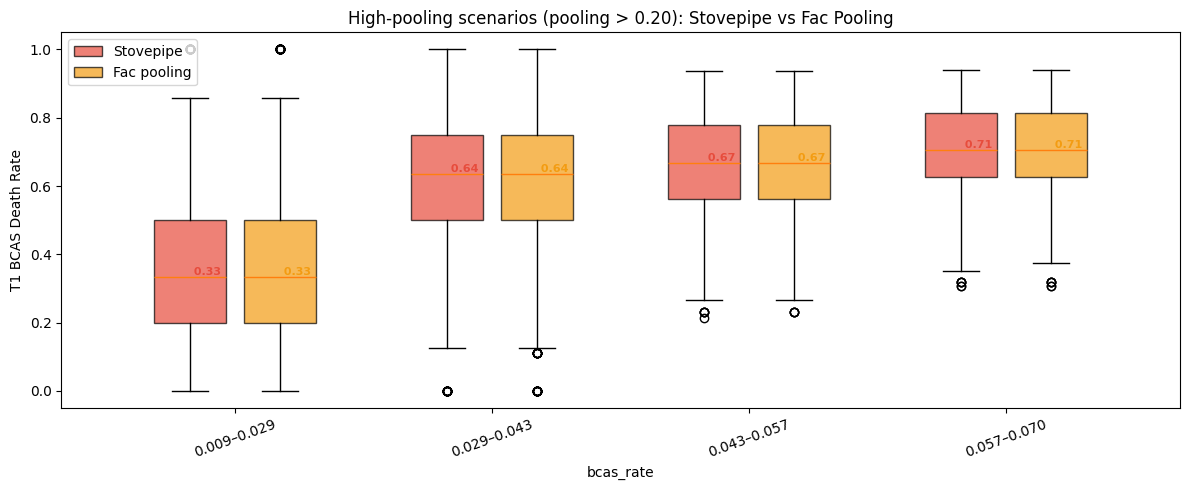

0.009–0.029: stove median=0.333, fac median=0.333, delta median=0.0000
0.029–0.043: stove median=0.636, fac median=0.636, delta median=0.0000
0.043–0.057: stove median=0.667, fac median=0.667, delta median=0.0000
0.057–0.070: stove median=0.706, fac median=0.706, delta median=0.0000


In [38]:
# Among high-pooling scenarios, compare fac pooling vs stovepipe by bcas bin
high_stove = stove_sorted.loc[high.index].copy()

bins = pd.qcut(high["bcas_rate"], q=4, duplicates="drop")
bin_labels = [f"{iv.left:.3f}–{iv.right:.3f}" for iv in sorted(bins.unique().dropna())]

fig, ax = plt.subplots(figsize=(12, 5))

x_pos = np.arange(len(bin_labels))
w = 0.35

# Stovepipe boxplots
groups_stove = high_stove.groupby(bins, observed=True)
data_stove = [g["death_rate_T1_BCAS"].values for _, g in groups_stove]
bp1 = ax.boxplot(data_stove, positions=x_pos - w/2, widths=w*0.8, patch_artist=True)
for patch in bp1["boxes"]:
    patch.set_facecolor("#e74c3c")
    patch.set_alpha(0.7)

# Fac pooling boxplots
high_binned = high.copy()
high_binned["_bin"] = bins
groups_fac = high_binned.groupby("_bin", observed=True)
data_fac = [g["death_rate_T1_BCAS"].values for _, g in groups_fac]
bp2 = ax.boxplot(data_fac, positions=x_pos + w/2, widths=w*0.8, patch_artist=True)
for patch in bp2["boxes"]:
    patch.set_facecolor("#f39c12")
    patch.set_alpha(0.7)

# Medians
for i, (ds, df_) in enumerate(zip(data_stove, data_fac)):
    ax.text(i - w/2, np.median(ds), f" {np.median(ds):.2f}", va="bottom", fontsize=8, fontweight="bold", color="#e74c3c")
    ax.text(i + w/2, np.median(df_), f" {np.median(df_):.2f}", va="bottom", fontsize=8, fontweight="bold", color="#f39c12")

ax.set_xticks(x_pos)
ax.set_xticklabels(bin_labels, rotation=20)
ax.set_xlabel("bcas_rate")
ax.set_ylabel("T1 BCAS Death Rate")
ax.set_title(f"High-pooling scenarios (pooling > {median_pooling:.2f}): Stovepipe vs Fac Pooling")
ax.legend([bp1["boxes"][0], bp2["boxes"][0]], ["Stovepipe", "Fac pooling"], loc="upper left")
plt.tight_layout()
plt.show()

# Print summary
for i, (bl, ds, df_) in enumerate(zip(bin_labels, data_stove, data_fac)):
    print(f"{bl}: stove median={np.median(ds):.3f}, fac median={np.median(df_):.3f}, delta median={np.median(df_) - np.median(ds):.4f}")

## High-Pooling Scenarios: Wait for Care at R1 vs BCAS — With and Without Pooling

Scenarios matching filter: 1284
Pooling usage: median=0.389, mean=0.364


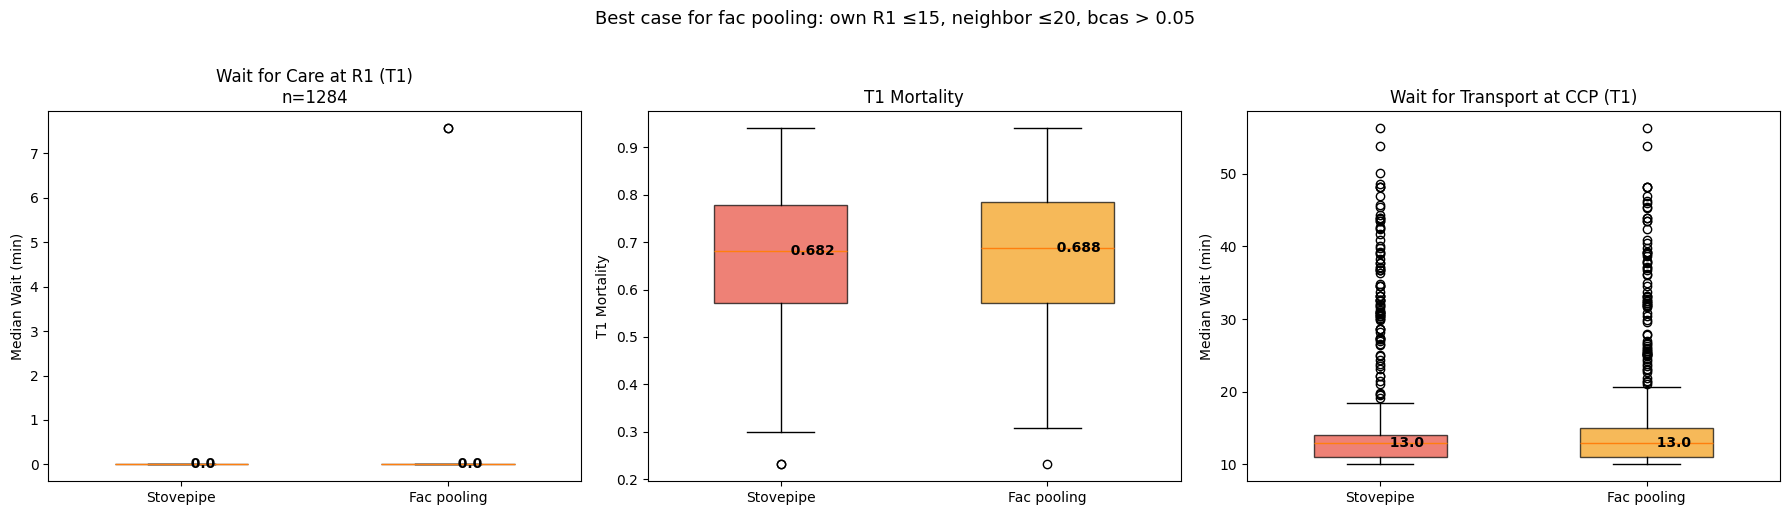


R1 care wait:  stove=0.0, fac=0.0
CCP transport: stove=13.0, fac=13.0
Mortality:     stove=0.682, fac=0.688
Pooling usage: 0.389


In [40]:
# Restrict to: own R1 close (10-15), neighbor close (15-20), high bcas (>0.05)
OUTCOME = "median_wait_r1_care_T1"

stress_mask = (
    (fac_sorted["ccp_r1_same_bn_min"] <= 15) &
    (fac_sorted["ccp_r1_inter_bn_min"] <= 20) &
    (fac_sorted["bcas_rate"] > 0.05)
)
high_stress_fac = fac_sorted[stress_mask]
high_stress_stove = stove_sorted.loc[high_stress_fac.index]

print(f"Scenarios matching filter: {len(high_stress_fac)}")
print(f"Pooling usage: median={high_stress_fac['frac_facility_cross_bn'].median():.3f}, mean={high_stress_fac['frac_facility_cross_bn'].mean():.3f}")

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Wait for care at R1
data = [high_stress_stove[OUTCOME].dropna().values, high_stress_fac[OUTCOME].dropna().values]
bp = axes[0].boxplot(data, tick_labels=["Stovepipe", "Fac pooling"], patch_artist=True, widths=0.5)
for patch, color in zip(bp["boxes"], ["#e74c3c", "#f39c12"]):
    patch.set_facecolor(color)
    patch.set_alpha(0.7)
for i, d in enumerate(data):
    med = np.median(d)
    axes[0].text(i + 1, med, f"  {med:.1f}", va="center", fontsize=10, fontweight="bold")
axes[0].set_ylabel("Median Wait (min)")
axes[0].set_title(f"Wait for Care at R1 (T1)\nn={len(high_stress_fac)}")

# Mortality
data_mort = [high_stress_stove["death_rate_T1_BCAS"].values, high_stress_fac["death_rate_T1_BCAS"].values]
bp2 = axes[1].boxplot(data_mort, tick_labels=["Stovepipe", "Fac pooling"], patch_artist=True, widths=0.5)
for patch, color in zip(bp2["boxes"], ["#e74c3c", "#f39c12"]):
    patch.set_facecolor(color)
    patch.set_alpha(0.7)
for i, d in enumerate(data_mort):
    med = np.median(d)
    axes[1].text(i + 1, med, f"  {med:.3f}", va="center", fontsize=10, fontweight="bold")
axes[1].set_ylabel("T1 Mortality")
axes[1].set_title("T1 Mortality")

# Wait for transport at CCP
data_ccp = [high_stress_stove["median_wait_ccp_transport_T1"].dropna().values, high_stress_fac["median_wait_ccp_transport_T1"].dropna().values]
bp3 = axes[2].boxplot(data_ccp, tick_labels=["Stovepipe", "Fac pooling"], patch_artist=True, widths=0.5)
for patch, color in zip(bp3["boxes"], ["#e74c3c", "#f39c12"]):
    patch.set_facecolor(color)
    patch.set_alpha(0.7)
for i, d in enumerate(data_ccp):
    med = np.median(d)
    axes[2].text(i + 1, med, f"  {med:.1f}", va="center", fontsize=10, fontweight="bold")
axes[2].set_ylabel("Median Wait (min)")
axes[2].set_title("Wait for Transport at CCP (T1)")

fig.suptitle("Best case for fac pooling: own R1 ≤15, neighbor ≤20, bcas > 0.05", fontsize=13, y=1.02)
plt.tight_layout()
plt.show()

print(f"\nR1 care wait:  stove={np.median(data[0]):.1f}, fac={np.median(data[1]):.1f}")
print(f"CCP transport: stove={np.median(data_ccp[0]):.1f}, fac={np.median(data_ccp[1]):.1f}")
print(f"Mortality:     stove={np.median(data_mort[0]):.3f}, fac={np.median(data_mort[1]):.3f}")
print(f"Pooling usage: {high_stress_fac['frac_facility_cross_bn'].median():.3f}")